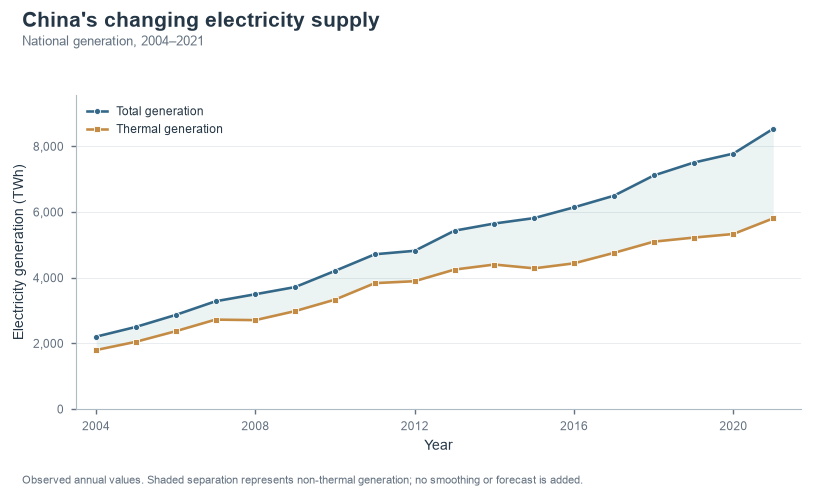

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

# Start the kernel in this project directory, or set PROJECT_ROOT explicitly.
PROJECT_ROOT = Path.cwd()
DATA_DIR = PROJECT_ROOT / "data"
if not DATA_DIR.is_dir():
    raise FileNotFoundError("请在包含 data 文件夹的项目目录中启动 Notebook，或修改 PROJECT_ROOT。")

from plotting import figures as figure_style
OUTPUT_DIR = PROJECT_ROOT / "analysis_outputs"
figure_style.configure(OUTPUT_DIR)

province_labels = {
    "北京市": "Beijing", "天津市": "Tianjin", "河北省": "Hebei", "山西省": "Shanxi",
    "内蒙古自治区": "Inner Mongolia", "辽宁省": "Liaoning", "吉林省": "Jilin",
    "黑龙江省": "Heilongjiang", "上海市": "Shanghai", "江苏省": "Jiangsu",
    "浙江省": "Zhejiang", "安徽省": "Anhui", "福建省": "Fujian", "江西省": "Jiangxi",
    "山东省": "Shandong", "河南省": "Henan", "湖北省": "Hubei", "湖南省": "Hunan",
    "广东省": "Guangdong", "广西壮族自治区": "Guangxi", "海南省": "Hainan",
    "重庆市": "Chongqing", "四川省": "Sichuan", "贵州省": "Guizhou", "云南省": "Yunnan",
    "西藏自治区": "Tibet", "陕西省": "Shaanxi", "甘肃省": "Gansu", "青海省": "Qinghai",
    "宁夏回族自治区": "Ningxia", "新疆维吾尔自治区": "Xinjiang",
}

df = pd.read_csv(f"{DATA_DIR}/分省年度数据.csv")
df = df.replace([np.inf, -np.inf], np.nan)
df = df[["时间", "总计", "火力发电总计"]].copy()
df["时间"] = pd.to_numeric(df["时间"], errors="coerce")
df = df.dropna(subset=["时间"]).sort_values("时间")

figure_style.national_generation(df)


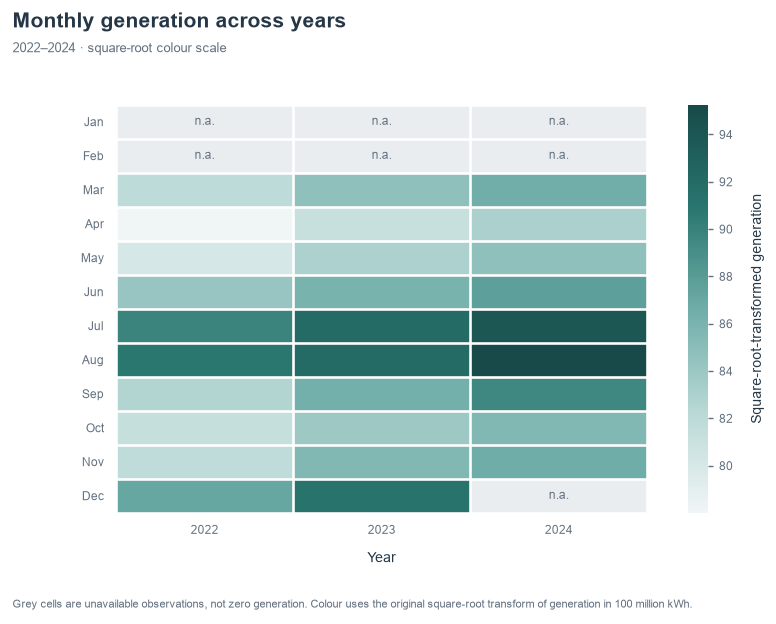

In [2]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

monthly = pd.read_excel(f"{DATA_DIR}/月度数据.xls")
monthly["年份"] = monthly["时间"].str.extract(r"(\d{4})年").astype(int)
monthly["月份"] = monthly["时间"].str.extract(r"年(\d{1,2})月").astype(int)
monthly = monthly[monthly["年份"] >= monthly["年份"].max() - 2].copy()
monthly["sqrt_generation"] = np.sqrt(monthly["发电量当期值(亿千瓦时)"])
monthly["月份"] = pd.Categorical(monthly["月份"], categories=range(1, 13), ordered=True)
pivot = monthly.pivot_table(index="月份", columns="年份", values="sqrt_generation", observed=False)
# Keep unavailable months in their calendar positions; never replace them with zero.
pivot = pivot.reindex(range(1, 13))

figure_style.monthly_heatmap(pivot)


In [3]:
import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt


In [4]:
china_map = gpd.read_file(f"{DATA_DIR}/中华人民共和国.shp")
annual = pd.read_csv(f"{DATA_DIR}/分省年度数据(转置).csv")[["地区", "2020年"]].copy()
annual = annual[annual["地区"] != "总计"]

province_info = pd.read_excel(f"{DATA_DIR}/省份地理信息.xlsx")
province_points = gpd.GeoDataFrame(
    province_info,
    geometry=gpd.points_from_xy(province_info["long"], province_info["lat"]),
    crs=china_map.crs,
)
province_matches = gpd.sjoin(
    province_points,
    china_map[["geometry"]],
    how="left",
    predicate="within",
)
if province_matches["index_right"].isna().any():
    unmatched = province_matches.loc[province_matches["index_right"].isna(), "name"].tolist()
    raise ValueError(f"Could not match province coordinates to map polygons: {unmatched}")

province_shapes = china_map.iloc[province_matches["index_right"].astype(int).to_numpy()].copy()
province_shapes = province_shapes.reset_index(drop=True)
province_shapes["地区"] = province_matches["name"].to_numpy()
map_data = province_shapes.merge(annual, on="地区", how="inner")

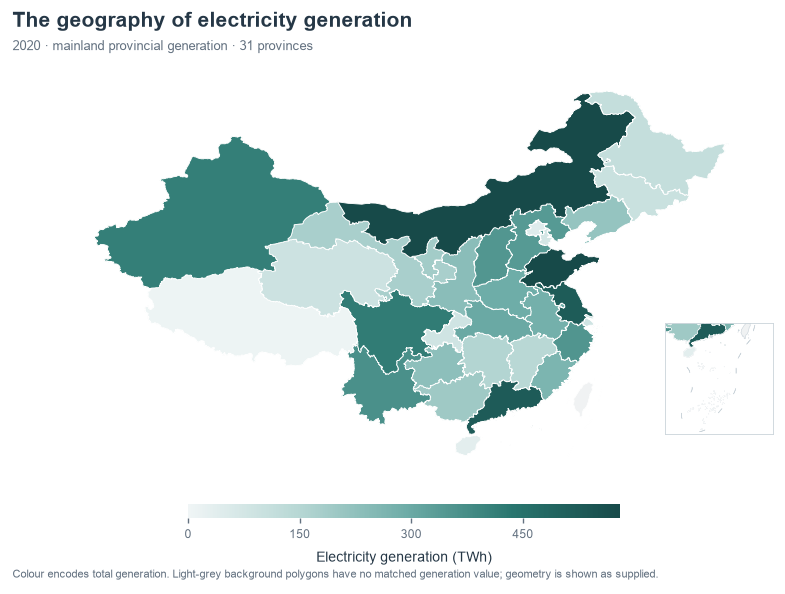

In [5]:
figure_style.province_map(map_data, china_map)

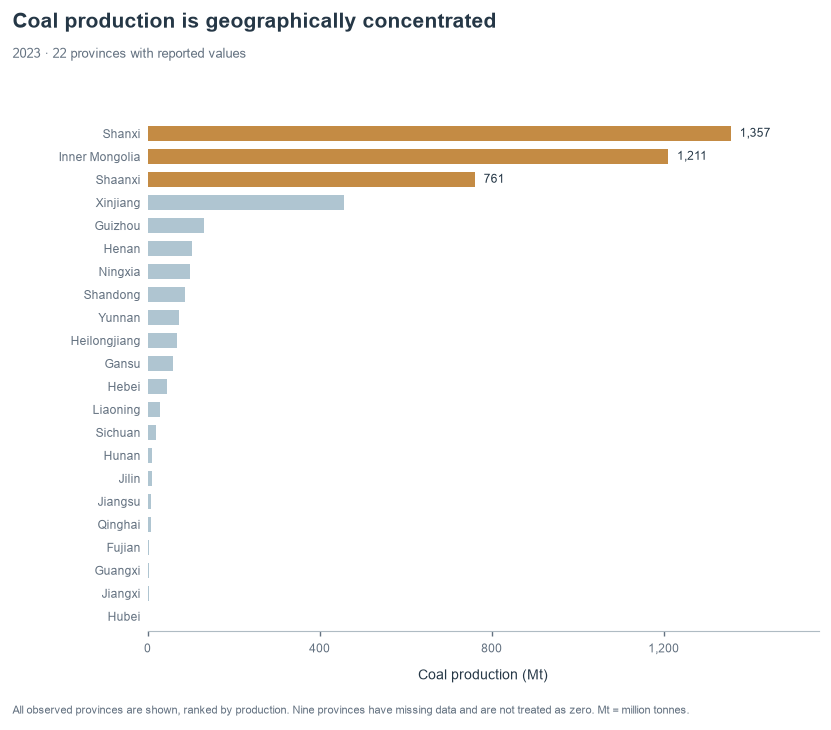

In [6]:
import pandas as pd
import matplotlib.pyplot as plt

coal = pd.read_excel(f"{DATA_DIR}/煤产量数据.xls")
coal["2023煤炭产量(万吨)"] = pd.to_numeric(coal["2023煤炭产量(万吨)"], errors="coerce")
coal = coal.dropna(subset=["2023煤炭产量(万吨)"])
coal["Province"] = coal["地区"].map(province_labels).fillna(coal["地区"])

by_province = coal.groupby("Province")["2023煤炭产量(万吨)"].sum().sort_values()

figure_style.coal_production(by_province)


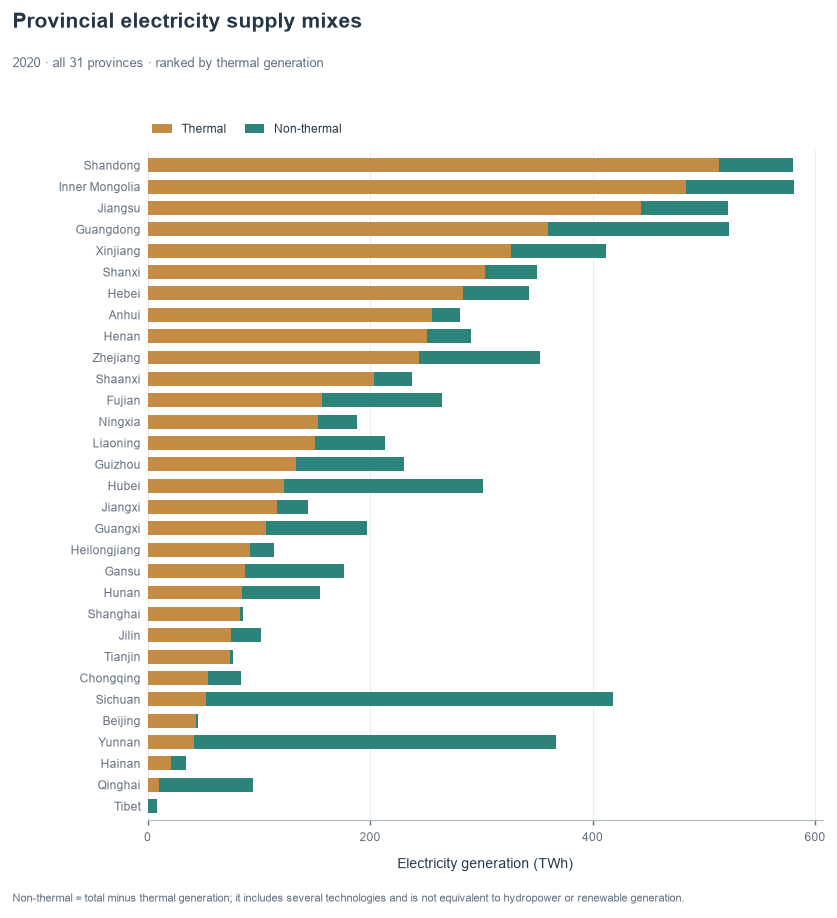

In [7]:
import pandas as pd
import matplotlib.pyplot as plt

thermal = pd.read_excel(f"{DATA_DIR}/火力发电数据2020.xls")
thermal["其他发电量"] = thermal["总计"] - thermal["2020火力发电量"]
thermal = thermal.sort_values("2020火力发电量", ascending=False).copy()
thermal["Province"] = thermal["地区"].map(province_labels).fillna(thermal["地区"])

figure_style.thermal_mix(thermal)


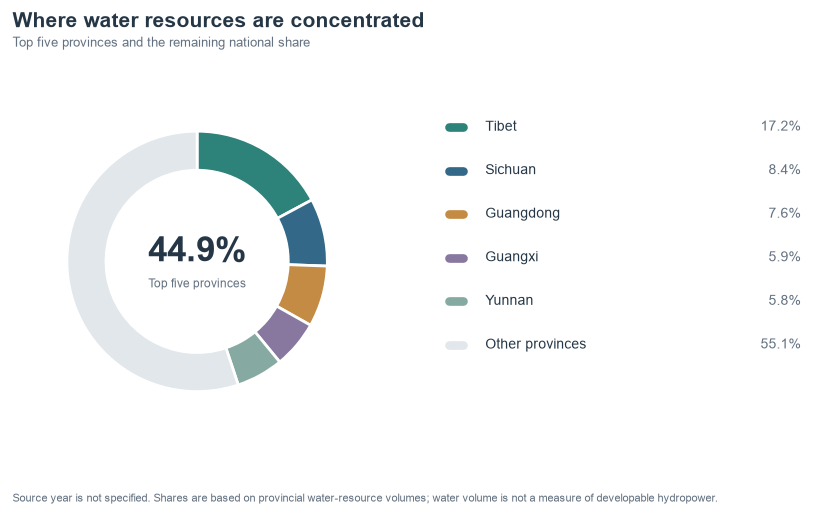

In [8]:
import pandas as pd
import matplotlib.pyplot as plt

water = pd.read_excel(f"{DATA_DIR}/水资源总量.xls")
water = water[water["地区"] != "全国"].copy()
water = water.sort_values("水资源总量(亿立方米)", ascending=False)
top = water.head(5).copy()
others = pd.DataFrame({"地区": ["Other"], "水资源总量(亿立方米)": [water["水资源总量(亿立方米)"].sum() - top["水资源总量(亿立方米)"].sum()]})
pie_data = pd.concat([top, others], ignore_index=True)
pie_data["Region"] = pie_data["地区"].map(province_labels).fillna(pie_data["地区"])

figure_style.water_resources(pie_data)


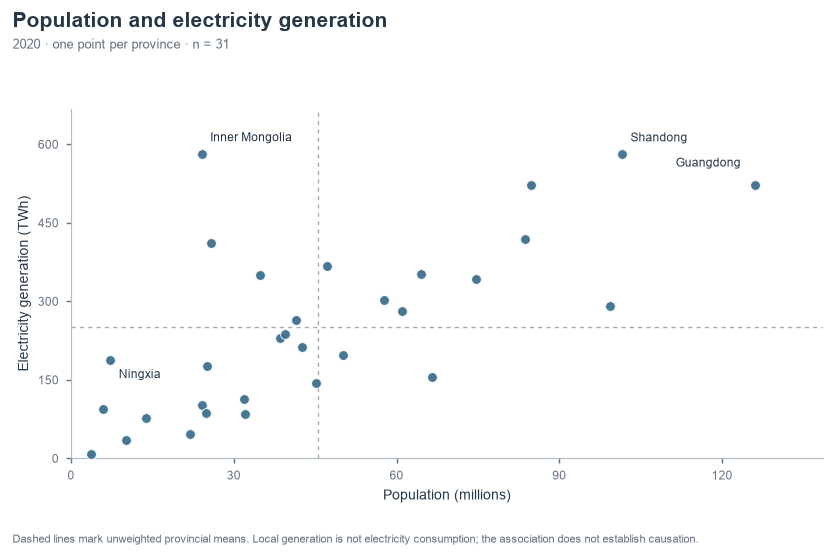

In [9]:
import pandas as pd
import matplotlib.pyplot as plt

annual = pd.read_csv(f"{DATA_DIR}/分省年度数据(转置).csv")[["地区", "2020年"]].copy()
annual = annual[annual["地区"] != "总计"]
population = pd.read_excel(f"{DATA_DIR}/省份地理信息.xlsx")
population = population[~population["name"].isin(["香港特别行政区", "澳门特别行政区", "台湾省"])]
combined = annual.merge(population[["name", "people"]], left_on="地区", right_on="name", how="inner")
combined["Population (100 million)"] = combined["people"] / 1e8
combined["Province"] = combined["地区"].map(province_labels).fillna(combined["地区"])

figure_style.population_generation(combined)


## 省际差异、关系验证与解释

本节从“画出差异”推进到“量化差异、验证关联、解释边界”。分析对象为大陆 31 个省级行政区，基准年为 **2020 年**；年度变化覆盖 2004—2021 年，月度比较使用 2022—2024 年共同具备的 3—11 月。

分析顺序：数据核验 → 总量、人均和发电结构 → 四大区域比较 → 人口、煤炭、水资源关系的稳健性 → 控制人口后的比较 → 时间变化 → 结论与后续验证。

人口与发电量可按 2020 年配对；煤炭为 2023 年，水资源年份缺失，涉及后两者的结果均为探索性关联，不能证明 2020 年的资源驱动效应。非火电 = 总发电量 − 火电，包含多种发电方式，不能直接称为水电或可再生能源；火电也不能直接等同于煤电。

图表已统一采用科学报告样式：一致的字体、语义配色、面板标记和留白；省份图保留所有观测。展示单位部分转换为 TWh、Mt 和十亿立方米，原始数据及统计计算保持原单位。每幅图随运行导出为高清 PNG、矢量 PDF 和可编辑 SVG，保存至 `analysis_outputs/`。

月度热力图原透视表会省略全空的1—2月；现已显式补齐1—12月网格，修正月份标签错位。缺失值仍保留为空，不影响任何已有数值或关系检验。

In [10]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter, MaxNLocator
from scipy import stats
import statsmodels.api as sm
from statsmodels.stats.multitest import multipletests
from IPython.display import display, Markdown

OUTPUT_DIR = PROJECT_ROOT / "analysis_outputs"
OUTPUT_DIR.mkdir(exist_ok=True)
figure_style.configure(OUTPUT_DIR)

def show_table(frame, decimals=3):
    display(frame.round(decimals))

def finish_figure(fig, name):
    fig.savefig(OUTPUT_DIR / f"{name}.png", dpi=160, bbox_inches="tight")
    plt.show()
    plt.close(fig)

annual_source = pd.read_csv(DATA_DIR / "分省年度数据(转置).csv")
annual_wide = pd.read_csv(DATA_DIR / "分省年度数据.csv").set_index("时间").sort_index()
thermal_source = pd.read_excel(DATA_DIR / "火力发电数据2020.xls")
population_source = pd.read_excel(DATA_DIR / "省份地理信息.xlsx")
coal_source = pd.read_excel(DATA_DIR / "煤产量数据.xls")
water_source = pd.read_excel(DATA_DIR / "水资源总量.xls")

annual_provinces = annual_source.loc[annual_source["地区"] != "总计"].copy()
province_names = set(annual_provinces["地区"])
assert len(province_names) == 31
for source, key in [(annual_source, "地区"), (thermal_source, "地区"),
                    (population_source, "name"), (coal_source, "地区"), (water_source, "地区")]:
    assert not source[key].duplicated().any(), f"Duplicate province key: {key}"
    assert province_names.issubset(set(source[key])), f"Missing province keys: {key}"

analysis = annual_provinces.rename(columns={"2020年": "generation_2020"})
analysis = analysis.merge(
    thermal_source.rename(columns={"2020火力发电量": "thermal_2020", "总计": "thermal_file_total"}),
    on="地区", how="left", validate="one_to_one")
analysis = analysis.merge(population_source[["name", "people"]], left_on="地区", right_on="name",
                          how="left", validate="one_to_one")
analysis = analysis.merge(coal_source.rename(columns={"2023煤炭产量(万吨)": "coal_2023"}),
                          on="地区", how="left", validate="one_to_one")
analysis = analysis.merge(water_source.rename(columns={"水资源总量(亿立方米)": "water_unknown_year"}),
                          on="地区", how="left", validate="one_to_one")
required = ["generation_2020", "thermal_2020", "thermal_file_total", "people", "water_unknown_year"]
for col in required + ["coal_2023"]:
    analysis[col] = pd.to_numeric(analysis[col], errors="coerce")
assert analysis[required].notna().all().all()
assert np.isfinite(analysis[required]).all().all()
assert (analysis[required] > 0).all().all()
assert np.isfinite(analysis["coal_2023"].dropna()).all()
assert (analysis["coal_2023"].dropna() > 0).all()
assert np.allclose(analysis.generation_2020, analysis.thermal_file_total, rtol=0, atol=0.01)
assert (analysis.thermal_2020 <= analysis.generation_2020).all()

# NBS seventh population census, communiqué No. 3, table 3-1.
# A source snapshot makes the 2020 population-year verification reproducible offline.
official_population_2020 = {
    "北京市": 21893095, "天津市": 13866009, "河北省": 74610235, "山西省": 34915616,
    "内蒙古自治区": 24049155, "辽宁省": 42591407, "吉林省": 24073453, "黑龙江省": 31850088,
    "上海市": 24870895, "江苏省": 84748016, "浙江省": 64567588, "安徽省": 61027171,
    "福建省": 41540086, "江西省": 45188635, "山东省": 101527453, "河南省": 99365519,
    "湖北省": 57752557, "湖南省": 66444864, "广东省": 126012510, "广西壮族自治区": 50126804,
    "海南省": 10081232, "重庆市": 32054159, "四川省": 83674866, "贵州省": 38562148,
    "云南省": 47209277, "西藏自治区": 3648100, "陕西省": 39528999, "甘肃省": 25019831,
    "青海省": 5923957, "宁夏回族自治区": 7202654, "新疆维吾尔自治区": 25852345,
}
assert analysis.people.eq(analysis["地区"].map(official_population_2020)).all()
analysis["Province"] = analysis["地区"].map(province_labels)
assert analysis.Province.notna().all()
analysis["other_2020"] = analysis.generation_2020 - analysis.thermal_2020
analysis["thermal_share"] = analysis.thermal_2020 / analysis.generation_2020
analysis["other_share"] = 1 - analysis.thermal_share
analysis["generation_per_capita_kwh"] = analysis.generation_2020 * 1e8 / analysis.people
analysis["generation_share"] = analysis.generation_2020 / analysis.generation_2020.sum()
analysis["population_share"] = analysis.people / analysis.people.sum()
analysis["relative_generation_per_capita"] = analysis.generation_share / analysis.population_share

regions = {
    "East": ["北京市", "天津市", "河北省", "上海市", "江苏省", "浙江省", "福建省", "山东省", "广东省", "海南省"],
    "Central": ["山西省", "安徽省", "江西省", "河南省", "湖北省", "湖南省"],
    "West": ["内蒙古自治区", "广西壮族自治区", "重庆市", "四川省", "贵州省", "云南省", "西藏自治区", "陕西省", "甘肃省", "青海省", "宁夏回族自治区", "新疆维吾尔自治区"],
    "Northeast": ["辽宁省", "吉林省", "黑龙江省"],
}
region_lookup = {province: region for region, provinces in regions.items() for province in provinces}
analysis["Region"] = analysis["地区"].map(region_lookup)
assert analysis.Region.notna().all()

audit = pd.DataFrame([
    ["分省年度数据(转置).csv / 分省年度数据.csv", "2004—2021", "亿千瓦时", 31, "无；两种排布交叉核对"],
    ["火力发电数据2020.xls", "2020", "亿千瓦时", 31, "无；总计与年度表逐省核对"],
    ["省份地理信息.xlsx / people", "2020普查时点", "人", 31, "31省人口均与官方表3-1一致；排除港澳台行"],
    ["煤产量数据.xls", "2023", "万吨", int(analysis.coal_2023.notna().sum()), "9省缺失，不补零；跨年探索"],
    ["水资源总量.xls", "未标注", "亿立方米", 31, "不擅自补定年份；不等于水能可开发量"],
    ["月度数据.xls", "2021-12至2024-11", "亿千瓦时", np.nan, "1—2月均缺失；2024年12月缺失"],
], columns=["本地来源", "年份", "单位", "有效省份数", "核验与限制"])
show_table(audit)

year_columns = sorted([col for col in annual_provinces if col.endswith("年")], key=lambda s: int(s[:-1]))
reconciliation = []
for col in year_columns:
    year = int(col[:-1])
    values = annual_provinces[col].to_numpy(dtype=float)
    assert np.isfinite(values).all() and (values > 0).all()
    ordered = annual_provinces.set_index("地区")[col]
    assert np.allclose(ordered, annual_wide.loc[year, ordered.index].astype(float), rtol=0, atol=0.01)
    national = float(annual_source.loc[annual_source["地区"] == "总计", col].iloc[0])
    delta = float(values.sum() - national)
    reconciliation.append([year, values.sum(), national, delta])
reconciliation = pd.DataFrame(reconciliation, columns=["Year", "Province sum", "National row", "Difference"])
assert reconciliation.Difference.abs().max() < 0.05
assert np.isclose(analysis.thermal_2020.sum(), annual_wide.loc[2020, "火力发电总计"], rtol=0, atol=0.05)
assert np.isclose(analysis.water_unknown_year.sum(), water_source.loc[water_source["地区"] == "全国", "水资源总量(亿立方米)"].iloc[0], rtol=0, atol=0.05)
display(Markdown(f"核验通过：31省匹配完整，18年省份加总与全国行最大差额 **{reconciliation.Difference.abs().max():.4f} 亿千瓦时**；2020年火电合计、水资源合计也与各自全国值一致。煤炭缺失省份：{'、'.join(analysis.loc[analysis.coal_2023.isna(), '地区'])}。人口合计不含现役军人，故人均基准用31省人口之和。"))
audit.to_csv(OUTPUT_DIR / "data_audit.csv", index=False, encoding="utf-8-sig")

,本地来源,年份,单位,有效省份数,核验与限制
0,分省年度数据(转置).csv / 分省年度数据.csv,2004—2021,亿千瓦时,31.0,无；两种排布交叉核对
1,火力发电数据2020.xls,2020,亿千瓦时,31.0,无；总计与年度表逐省核对
2,省份地理信息.xlsx / people,2020普查时点,人,31.0,31省人口均与官方表3-1一致；排除港澳台行
3,煤产量数据.xls,2023,万吨,22.0,9省缺失，不补零；跨年探索
4,水资源总量.xls,未标注,亿立方米,31.0,不擅自补定年份；不等于水能可开发量
5,月度数据.xls,2021-12至2024-11,亿千瓦时,NaN,1—2月均缺失；2024年12月缺失


核验通过：31省匹配完整，18年省份加总与全国行最大差额 **0.0000 亿千瓦时**；2020年火电合计、水资源合计也与各自全国值一致。煤炭缺失省份：北京市、天津市、上海市、浙江省、安徽省、广东省、海南省、重庆市、西藏自治区。人口合计不含现役军人，故人均基准用31省人口之和。

### 1. 差异有多大：总量、人均、结构分开比较

总量衡量本地发电规模；人均发电量 = 发电量（亿千瓦时）× 10⁸ ÷ 常住人口，衡量相对于人口的发电规模，**不代表居民用电量，也不能判定电力净输出**。非火电占比反映发电结构。

集中度 CR5 为前五省份占比；CV 为31省总体标准差除以均值；Gini 为等权省份发电量的差异指标，越高表示省际规模越不均衡，不能解释为居民用电不平等。最大/最小值比容易受西藏等极端规模影响，同时报告 P90/P10。

,数值
2020年总发电量（亿千瓦时）,77790.570
前五省份占比 CR5,0.337
省际CV（总体标准差/均值）,0.640
省际Gini（等权省份）,0.362
总量最大/最小,65.365
总量P90/P10,6.762
31省合计人均发电量（kWh/人）,5517.928
全国火电占比,0.685


,地区,Region,generation_rank,发电量_亿kWh,generation_share,per_capita_rank,人均发电量_kWh,relative_generation_per_capita,thermal_share,other_share
4,内蒙古自治区,West,1,5810.97,0.075,2,24162.886,4.379,0.833,0.167
14,山东省,East,2,5806.43,0.075,12,5719.074,1.036,0.885,0.115
18,广东省,East,3,5225.91,0.067,21,4147.136,0.752,0.689,0.311
9,江苏省,East,4,5217.54,0.067,9,6156.534,1.116,0.850,0.150
22,四川省,West,5,4182.28,0.054,17,4998.251,0.906,0.126,0.874
30,新疆维吾尔自治区,West,6,4121.86,0.053,4,15943.853,2.889,0.792,0.208
24,云南省,West,7,3674.44,0.047,6,7783.301,1.411,0.113,0.887
10,浙江省,East,8,3531.31,0.045,14,5469.168,0.991,0.692,0.308
3,山西省,Central,9,3503.54,0.045,5,10034.307,1.818,0.866,0.134
2,河北省,East,10,3425.07,0.044,19,4590.617,0.832,0.827,0.173


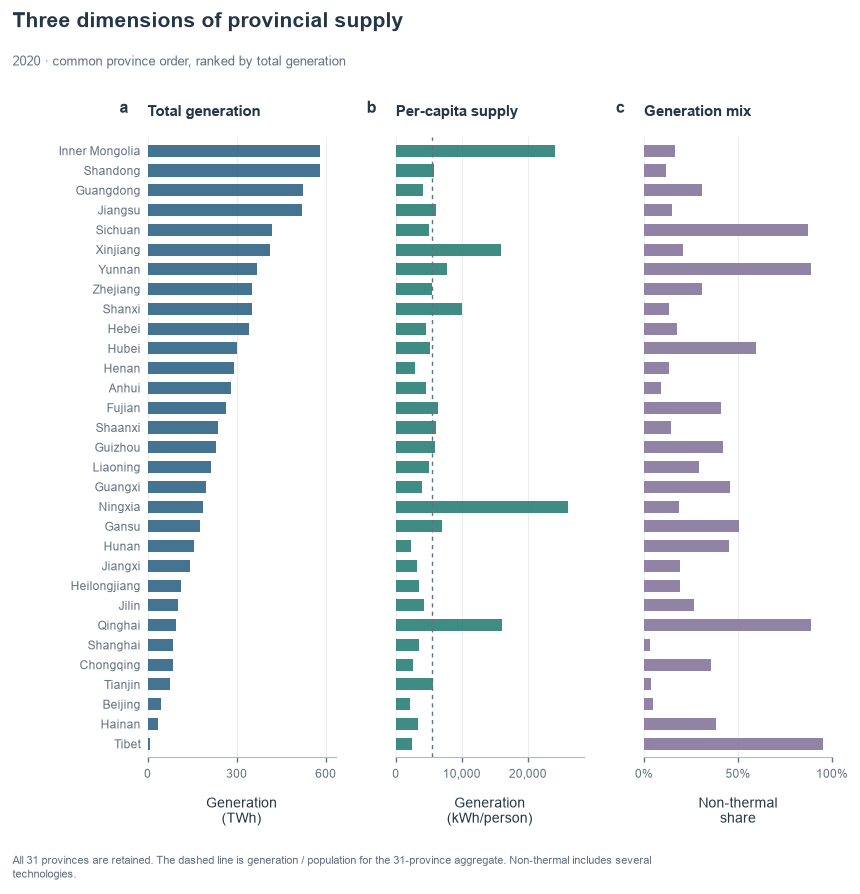

**读图与解释：**2020年发电量前五省为内蒙古自治区、山东省、广东省、江苏省、四川省，合计占比 **33.7%**。人均排名前五则为宁夏回族自治区、内蒙古自治区、青海省、新疆维吾尔自治区、山西省。宁夏为 **26,134 kWh/人**，广东为 **4,147 kWh/人**，说明总量排名会受人口规模影响。四川、云南非火电占比分别为 **87.4%、88.7%**；山东、内蒙古火电占比为 **88.5%、83.3%**，显示较不同的供给结构。资源、装机布局和跨省交易是可研究的解释，但本地人均发电量高本身不能证明净外送或高用电需求。

In [11]:
def gini(values):
    values = np.asarray(values, dtype=float)
    return np.abs(values[:, None] - values[None, :]).sum() / (2 * len(values) * values.sum())

generation = analysis.generation_2020
gap_metrics = pd.Series({
    "2020年总发电量（亿千瓦时）": generation.sum(),
    "前五省份占比 CR5": generation.nlargest(5).sum() / generation.sum(),
    "省际CV（总体标准差/均值）": generation.std(ddof=0) / generation.mean(),
    "省际Gini（等权省份）": gini(generation),
    "总量最大/最小": generation.max() / generation.min(),
    "总量P90/P10": generation.quantile(.9) / generation.quantile(.1),
    "31省合计人均发电量（kWh/人）": generation.sum() * 1e8 / analysis.people.sum(),
    "全国火电占比": analysis.thermal_2020.sum() / generation.sum(),
}, name="数值")
show_table(gap_metrics.to_frame())
analysis["generation_rank"] = generation.rank(ascending=False, method="min").astype(int)
analysis["per_capita_rank"] = analysis.generation_per_capita_kwh.rank(ascending=False, method="min").astype(int)
province_comparison = analysis[["地区", "Region", "generation_rank", "generation_2020", "generation_share",
                                "per_capita_rank", "generation_per_capita_kwh", "relative_generation_per_capita",
                                "thermal_share", "other_share"]].sort_values("generation_rank")
show_table(province_comparison.rename(columns={"generation_2020": "发电量_亿kWh", "generation_per_capita_kwh": "人均发电量_kWh"}))

figure_style.province_differences(analysis, gap_metrics["31省合计人均发电量（kWh/人）"])

ranked = analysis.sort_values("generation_2020", ascending=False)
pc_ranked = analysis.sort_values("generation_per_capita_kwh", ascending=False)
lookup = analysis.set_index("地区")
display(Markdown(
    f"**读图与解释：**2020年发电量前五省为{'、'.join(ranked.head(5)['地区'])}，合计占比 **{gap_metrics['前五省份占比 CR5']:.1%}**。"
    f"人均排名前五则为{'、'.join(pc_ranked.head(5)['地区'])}。宁夏为 **{lookup.loc['宁夏回族自治区', 'generation_per_capita_kwh']:,.0f} kWh/人**，"
    f"广东为 **{lookup.loc['广东省', 'generation_per_capita_kwh']:,.0f} kWh/人**，说明总量排名会受人口规模影响。"
    f"四川、云南非火电占比分别为 **{lookup.loc['四川省', 'other_share']:.1%}、{lookup.loc['云南省', 'other_share']:.1%}**；"
    f"山东、内蒙古火电占比为 **{lookup.loc['山东省', 'thermal_share']:.1%}、{lookup.loc['内蒙古自治区', 'thermal_share']:.1%}**，显示较不同的供给结构。"
    "资源、装机布局和跨省交易是可研究的解释，但本地人均发电量高本身不能证明净外送或高用电需求。"))
province_comparison.to_csv(OUTPUT_DIR / "province_comparison_2020.csv", index=False, encoding="utf-8-sig")

### 2. 区域比较：使用加总后的分母，检查区域内部差异

采用国家统计局东部、中部、西部、东北四大区域划分。区域人均发电量使用“区域发电量合计 / 区域人口合计”；区域火电占比使用“区域火电合计 / 区域总发电量合计”，避免简单平均省份比率造成误导。图中的散点同时展示区域内部各省差异。

,provinces,generation_2020,population_2020,thermal_2020,min_per_capita,max_per_capita,generation_share,generation_per_capita_kwh,thermal_share
Region,,,,,,,,,
East,10,28293.66,563717119,22241.43,2089.563,6381.908,0.364,5019.124,0.786
Central,6,15233.62,364694362,11344.97,2339.428,10034.307,0.196,4177.092,0.745
West,12,29971.36,382852295,16537.26,2436.885,26134.256,0.385,7828.439,0.552
Northeast,3,4291.93,98514948,3178.82,3572.486,5013.359,0.055,4356.628,0.741


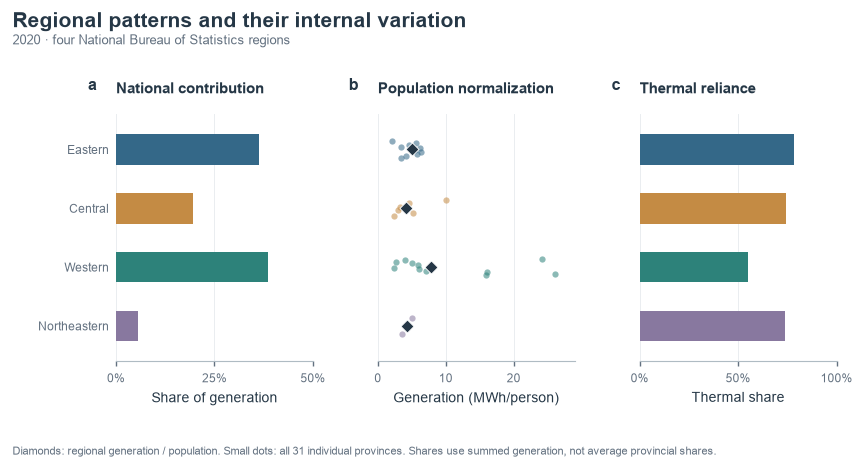

西部合计人均发电量为 **7,828 kWh/人**，东部为 **5,019 kWh/人**；西部内部范围为 **2,437—26,134 kWh/人**。因此区域汇总只能描述总体格局，不能把同一区域各省视为相同的能源类型；四川、云南与内蒙古、新疆需要结合发电结构分别解释。

In [12]:
region_order = ["East", "Central", "West", "Northeast"]
regional = analysis.groupby("Region").agg(
    provinces=("地区", "size"), generation_2020=("generation_2020", "sum"),
    population_2020=("people", "sum"), thermal_2020=("thermal_2020", "sum"),
    min_per_capita=("generation_per_capita_kwh", "min"), max_per_capita=("generation_per_capita_kwh", "max")
).reindex(region_order)
regional["generation_share"] = regional.generation_2020 / analysis.generation_2020.sum()
regional["generation_per_capita_kwh"] = regional.generation_2020 * 1e8 / regional.population_2020
regional["thermal_share"] = regional.thermal_2020 / regional.generation_2020
show_table(regional)

figure_style.regional_comparison(analysis, regional)
display(Markdown(
    f"西部合计人均发电量为 **{regional.loc['West', 'generation_per_capita_kwh']:,.0f} kWh/人**，东部为 **{regional.loc['East', 'generation_per_capita_kwh']:,.0f} kWh/人**；"
    f"西部内部范围为 **{regional.loc['West', 'min_per_capita']:,.0f}—{regional.loc['West', 'max_per_capita']:,.0f} kWh/人**。"
    "因此区域汇总只能描述总体格局，不能把同一区域各省视为相同的能源类型；四川、云南与内蒙古、新疆需要结合发电结构分别解释。"))
regional.to_csv(OUTPUT_DIR / "regional_comparison_2020.csv", encoding="utf-8-sig")

### 3. 关系是否稳健：相关系数、置换检验与逐省剔除

预先列出以下五组探索性比较，不按结果筛选：①人口—总发电量；②煤炭产量—火电量；③水资源—非火电量；④水资源—非火电占比；⑤水资源—总发电量。

- Pearson 描述原始数值的线性关系；Spearman 描述排序后的单调关系，降低极大数值的影响。
- 对每组完整配对数据做 19,999 次双侧随机置换，检验可交换条件下的独立性零假设；固定随机种子。五个置换 p 值统一做 Holm 校正。
- 逐次剔除一个省份并重新计算 Spearman，报告最小值、最大值及影响最大的省份，观察结论是否由单个省份支配。

这31省是研究对象全集，p 值不用于推断“未抽到的省份”；邻省关联、产业与电网联动可能破坏可交换性。检验为模型假设下的参考，不能替代效应大小、数据口径及因果识别。煤炭只对22个有值省份计算，结果不自动适用于缺失的9省。

,n,Pearson_r,Spearman_rho,permutation_p,Holm_p,LOO_rho_min,LOO_rho_max,most_influential_omission,年份口径
关系,,,,,,,,,
人口—总发电量,31,0.6767,0.6798,0.0000,0.0002,0.6467,0.7842,内蒙古自治区,2020 / 2020
煤炭产量—火电量,22,0.4848,0.4771,0.0244,0.0487,0.4117,0.5792,江苏省,2023 / 2020；22省完整样本
水资源—非火电量,31,0.3307,0.4623,0.0106,0.0318,0.4127,0.5763,西藏自治区,水资源年份未标 / 2020
水资源—非火电占比,31,0.6918,0.6856,0.0000,0.0002,0.6530,0.7563,甘肃省,水资源年份未标 / 2020
水资源—总发电量,31,-0.0540,0.1502,0.4198,0.4198,0.0848,0.2692,西藏自治区,水资源年份未标 / 2020


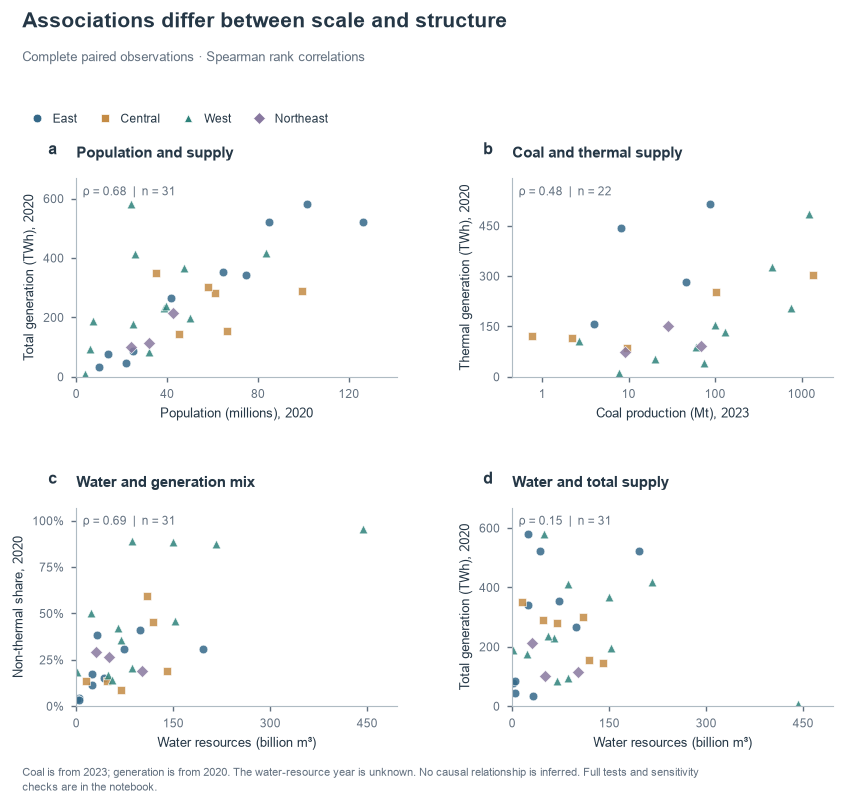

**验证结果：**人口—总发电量 Spearman ρ = **0.680**，逐省剔除范围为 **0.647—0.784**。煤炭—火电 ρ = **0.477**，仅适用于有煤炭数据的22省且存在三年错位。水资源—非火电占比 ρ = **0.686**，而水资源—总发电量仅为 **0.150**。数据更支持“水资源与发电结构有关”的探索性描述，不能推出“水资源越多，总发电量就越高”，也没有直接验证水电量。原始量级Pearson与排序Spearman的差别，以及逐省剔除结果，均见上表，不能只选择较强的一个系数报告。

In [13]:
relationship_specs = [
    ("人口—总发电量", "people", "generation_2020", "2020 / 2020"),
    ("煤炭产量—火电量", "coal_2023", "thermal_2020", "2023 / 2020；22省完整样本"),
    ("水资源—非火电量", "water_unknown_year", "other_2020", "水资源年份未标 / 2020"),
    ("水资源—非火电占比", "water_unknown_year", "other_share", "水资源年份未标 / 2020"),
    ("水资源—总发电量", "water_unknown_year", "generation_2020", "水资源年份未标 / 2020"),
]

def association_check(frame, x_col, y_col, seed):
    paired = frame[["地区", x_col, y_col]].dropna()
    x = paired[x_col].to_numpy(float)
    y = paired[y_col].to_numpy(float)
    rx = stats.rankdata(x)
    ry = stats.rankdata(y)
    rx = (rx - rx.mean()) / np.linalg.norm(rx - rx.mean())
    ry = (ry - ry.mean()) / np.linalg.norm(ry - ry.mean())
    rho = float(rx @ ry)
    rng = np.random.default_rng(seed)
    extreme = 0
    n_permutations = 19999
    for _ in range(n_permutations):
        permuted_rho = float(rx @ rng.permutation(ry))
        extreme += abs(permuted_rho) >= abs(rho) - 1e-12
    p_value = (extreme + 1) / (n_permutations + 1)
    leave_one_out = np.array([stats.spearmanr(np.delete(x, i), np.delete(y, i)).statistic for i in range(len(x))])
    influential = int(np.argmax(np.abs(leave_one_out - rho)))
    return {
        "n": len(paired), "Pearson_r": float(stats.pearsonr(x, y).statistic), "Spearman_rho": rho,
        "permutation_p": p_value, "LOO_rho_min": leave_one_out.min(), "LOO_rho_max": leave_one_out.max(),
        "most_influential_omission": paired.iloc[influential]["地区"],
    }

correlation_rows = []
for i, (label, x_col, y_col, period) in enumerate(relationship_specs):
    row = association_check(analysis, x_col, y_col, seed=5002 + i)
    row.update({"关系": label, "年份口径": period})
    correlation_rows.append(row)
correlations = pd.DataFrame(correlation_rows).set_index("关系")
correlations["Holm_p"] = multipletests(correlations.permutation_p, method="holm")[1]
show_table(correlations[["n", "Pearson_r", "Spearman_rho", "permutation_p", "Holm_p", "LOO_rho_min", "LOO_rho_max", "most_influential_omission", "年份口径"]], 4)

figure_style.relationship_checks(analysis, correlations)

correlations.to_csv(OUTPUT_DIR / "correlation_robustness.csv", encoding="utf-8-sig")
pop_relation = correlations.loc["人口—总发电量"]
coal_relation = correlations.loc["煤炭产量—火电量"]
water_share_relation = correlations.loc["水资源—非火电占比"]
water_total_relation = correlations.loc["水资源—总发电量"]
display(Markdown(
    f"**验证结果：**人口—总发电量 Spearman ρ = **{pop_relation.Spearman_rho:.3f}**，逐省剔除范围为 **{pop_relation.LOO_rho_min:.3f}—{pop_relation.LOO_rho_max:.3f}**。"
    f"煤炭—火电 ρ = **{coal_relation.Spearman_rho:.3f}**，仅适用于有煤炭数据的22省且存在三年错位。"
    f"水资源—非火电占比 ρ = **{water_share_relation.Spearman_rho:.3f}**，而水资源—总发电量仅为 **{water_total_relation.Spearman_rho:.3f}**。"
    "数据更支持“水资源与发电结构有关”的探索性描述，不能推出“水资源越多，总发电量就越高”，也没有直接验证水电量。"
    "原始量级Pearson与排序Spearman的差别，以及逐省剔除结果，均见上表，不能只选择较强的一个系数报告。"))

### 4. 控制人口规模后，资源变量还有多少额外解释力？

拟合对数线性 OLS，模型形式为 `ln(发电量) = 常数 + β₁ ln(人口) [+ β₂ ln(资源)]`。所有实际参与取对数的值均经检查为正。人口变量只代理规模，不能替代产业用电需求。

分别比较：31省总量的人口基准模型；相同22省样本上火电的“人口”与“人口+煤炭”模型；相同31省样本上总量的“人口”与“人口+水资源”模型。只有同一样本、同一因变量的模型才比较拟合和误差。

系数报告 HC3 异方差稳健95%置信区间（t参考分布）。调整R²描述样本内拟合；留一省交叉验证 RMSE 在对数尺度计算，每次重新拟合，衡量剔除一个省后对该省的预测偏差。资源系数另做逐省剔除检查。HC3不能消除空间依赖、遗漏变量或年份错位；以下模型均不识别因果。区间为单个系数的模型参考区间，没有做同时覆盖校正。

,outcome,n,adjusted_R2,LOO_RMSE_log
model,,,,
total_population_31,generation_2020,31,0.5459,0.6755
thermal_population_22,thermal_2020,22,0.1500,0.9598
thermal_population_coal_22,thermal_2020,22,0.3779,0.8189
total_population_water_31,generation_2020,31,0.5461,0.7253


,model,term,coefficient,HC3_CI_low,HC3_CI_high,LOO_coefficient_min,LOO_coefficient_max
0,total_population_31,people,0.8153,0.3517,1.2788,0.6448,0.9239
1,thermal_population_22,people,0.5395,-0.4955,1.5745,0.1278,0.7559
2,thermal_population_coal_22,people,0.6280,-0.2308,1.4868,0.3019,0.8299
3,thermal_population_coal_22,coal_2023,0.2195,0.0584,0.3805,0.1707,0.2457
4,total_population_water_31,people,0.8551,0.2984,1.4118,0.6244,0.9612
5,total_population_water_31,water_unknown_year,-0.0849,-0.4175,0.2477,-0.1403,0.0217


,地区,generation_2020,population_model_expected_generation,population_model_log_residual
4,内蒙古自治区,5810.97,1389.087,1.431
29,宁夏回族自治区,1882.36,519.802,1.287
30,新疆维吾尔自治区,4121.86,1473.430,1.029
28,青海省,951.95,443.237,0.764
3,山西省,3503.54,1882.525,0.621
24,云南省,3674.44,2407.409,0.423
9,江苏省,5217.54,3878.971,0.296
14,山东省,5806.43,4494.477,0.256
27,甘肃省,1762.35,1434.629,0.206
12,福建省,2651.05,2168.965,0.201


残差是相对于人口规模模型的偏离；exp(对数拟合值)为原尺度上的几何中心参考值，未作均值重变换校正。正残差不表示净外送，负残差不表示缺电。

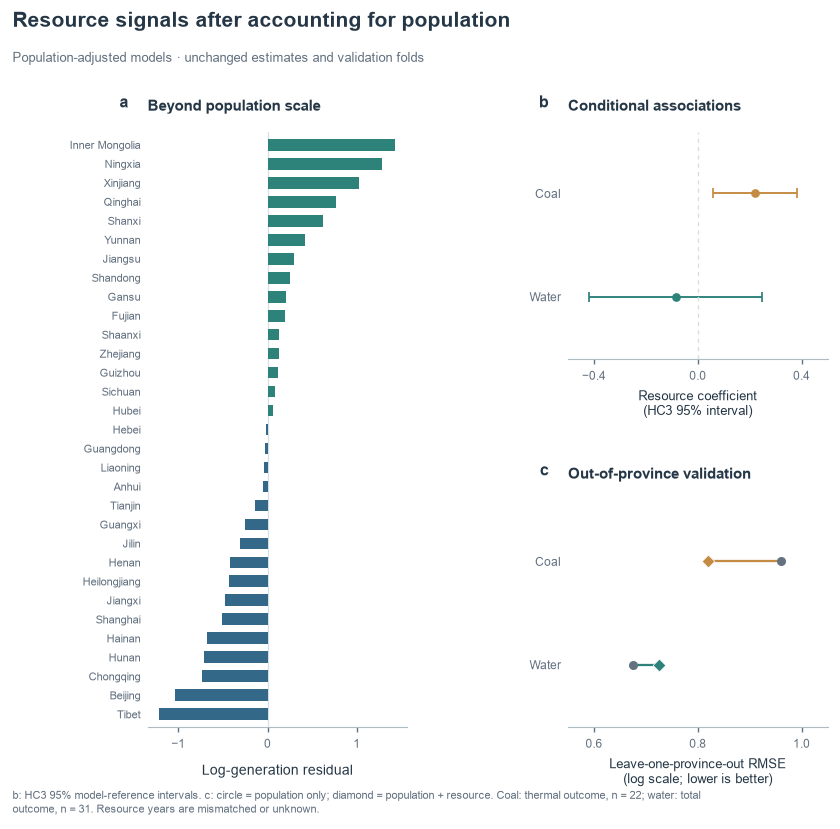

**模型解释：**31省人口基准模型调整R²为 **0.546**，人口系数 **0.815**（HC3区间 0.352—1.279）。这表明人口规模与发电量相关，但仍有明显的省际偏离，不能将拟合度当作人口造成发电差异的比例。22省样本加入煤炭后，煤炭系数为 **0.219**（0.058—0.380）；留一省RMSE从 **0.960** 变为 **0.819**。加入水资源后，其系数为 **-0.085**（-0.417—0.248），留一省RMSE从 **0.676** 变为 **0.725**。样本内拟合改善与留一省表现要同时查看；资源关联受年份错位和缺失样本影响，不能替代同年、分电源的数据验证。

In [14]:
model_specs = [
    ("total_population_31", "generation_2020", ["people"], None),
    ("thermal_population_22", "thermal_2020", ["people"], "coal_2023"),
    ("thermal_population_coal_22", "thermal_2020", ["people", "coal_2023"], "coal_2023"),
    ("total_population_water_31", "generation_2020", ["people", "water_unknown_year"], None),
]
models = {}
model_rows = []
coefficient_rows = []
for name, outcome, predictors, sample_restriction in model_specs:
    needed = list(dict.fromkeys([outcome] + predictors + ([sample_restriction] if sample_restriction else [])))
    sample = analysis.dropna(subset=needed).copy()
    X = sm.add_constant(np.log(sample[predictors]), has_constant="add")
    y = np.log(sample[outcome])
    model = sm.OLS(y, X).fit(cov_type="HC3", use_t=True)
    predictions_loo = []
    coefficients_loo = []
    for i in range(len(sample)):
        train = np.arange(len(sample)) != i
        refit = sm.OLS(y.iloc[train], X.iloc[train]).fit()
        predictions_loo.append(float(np.asarray(refit.predict(X.iloc[[i]]))[0]))
        coefficients_loo.append(refit.params)
    loo_rmse = np.sqrt(np.mean((y.to_numpy() - np.asarray(predictions_loo)) ** 2))
    models[name] = {"fit": model, "sample": sample, "X": X, "y": y,
                    "loo_coefficients": pd.DataFrame(coefficients_loo), "loo_log_rmse": loo_rmse}
    model_rows.append({"model": name, "outcome": outcome, "n": len(sample),
                       "adjusted_R2": model.rsquared_adj, "LOO_RMSE_log": loo_rmse})
    ci = model.conf_int()
    for term in predictors:
        coefficient_rows.append({"model": name, "term": term, "coefficient": model.params[term],
                                 "HC3_CI_low": ci.loc[term, 0], "HC3_CI_high": ci.loc[term, 1],
                                 "LOO_coefficient_min": models[name]["loo_coefficients"][term].min(),
                                 "LOO_coefficient_max": models[name]["loo_coefficients"][term].max()})
model_comparison = pd.DataFrame(model_rows).set_index("model")
coefficients = pd.DataFrame(coefficient_rows)
show_table(model_comparison, 4)
show_table(coefficients, 4)

baseline = models["total_population_31"]
analysis["population_model_expected_generation"] = np.exp(baseline["fit"].predict(baseline["X"]))
analysis["population_model_log_residual"] = baseline["fit"].resid
residual_comparison = analysis[["地区", "generation_2020", "population_model_expected_generation", "population_model_log_residual"]].sort_values("population_model_log_residual", ascending=False)
show_table(residual_comparison)
display(Markdown("残差是相对于人口规模模型的偏离；exp(对数拟合值)为原尺度上的几何中心参考值，未作均值重变换校正。正残差不表示净外送，负残差不表示缺电。"))

coal_ci = coefficients.loc[coefficients.term.eq("coal_2023")].iloc[0]
water_ci = coefficients.loc[coefficients.term.eq("water_unknown_year")].iloc[0]
figure_style.population_adjusted_models(analysis, coefficients, models)

pop_ci = coefficients.loc[(coefficients.model == "total_population_31") & (coefficients.term == "people")].iloc[0]
coal_baseline_rmse = models["thermal_population_22"]["loo_log_rmse"]
coal_added_rmse = models["thermal_population_coal_22"]["loo_log_rmse"]
water_baseline_rmse = models["total_population_31"]["loo_log_rmse"]
water_added_rmse = models["total_population_water_31"]["loo_log_rmse"]
display(Markdown(
    f"**模型解释：**31省人口基准模型调整R²为 **{baseline['fit'].rsquared_adj:.3f}**，人口系数 **{pop_ci.coefficient:.3f}**（HC3区间 {pop_ci.HC3_CI_low:.3f}—{pop_ci.HC3_CI_high:.3f}）。"
    "这表明人口规模与发电量相关，但仍有明显的省际偏离，不能将拟合度当作人口造成发电差异的比例。"
    f"22省样本加入煤炭后，煤炭系数为 **{coal_ci.coefficient:.3f}**（{coal_ci.HC3_CI_low:.3f}—{coal_ci.HC3_CI_high:.3f}）；"
    f"留一省RMSE从 **{coal_baseline_rmse:.3f}** 变为 **{coal_added_rmse:.3f}**。"
    f"加入水资源后，其系数为 **{water_ci.coefficient:.3f}**（{water_ci.HC3_CI_low:.3f}—{water_ci.HC3_CI_high:.3f}），"
    f"留一省RMSE从 **{water_baseline_rmse:.3f}** 变为 **{water_added_rmse:.3f}**。"
    "样本内拟合改善与留一省表现要同时查看；资源关联受年份错位和缺失样本影响，不能替代同年、分电源的数据验证。"))
model_comparison.to_csv(OUTPUT_DIR / "model_comparison.csv", encoding="utf-8-sig")
coefficients.to_csv(OUTPUT_DIR / "model_coefficients.csv", index=False, encoding="utf-8-sig")

### 5. 差异是否一直存在：2004—2021年趋势

每年使用相同31省计算 CV、Gini 和 CR5，区分“全国规模增长”和“省际相对差异变化”。省份 CAGR 只使用2004与2021两个端点，跨度17年；不能假定每年都按该速率增长。数据没有各省逐年人口，故不计算逐年人均发电趋势。

,Generation,CV,Gini,CR5,Thermal_share
Year,,,,,
2004,22033.09,0.7013,0.3831,0.3595,0.8150
2005,25002.60,0.7176,0.3912,0.3672,0.8188
2006,28657.26,0.7289,0.3974,0.3728,0.8269
2007,32815.50,0.7171,0.3939,0.3643,0.8298
2008,34957.60,0.6773,0.3769,0.3530,0.7744
2009,37146.51,0.6761,0.3787,0.3509,0.8030
2010,42071.60,0.6648,0.3710,0.3493,0.7920
2011,47130.19,0.6636,0.3694,0.3498,0.8134
2012,48187.50,0.6527,0.3656,0.3433,0.8078


,地区,2004年,2021年,CAGR,absolute_increase,Province
30,新疆维吾尔自治区,263.84,4683.55,0.1844,4419.71,Xinjiang
25,西藏自治区,11.51,112.77,0.1437,101.26,Tibet
29,宁夏回族自治区,253.66,2082.89,0.1319,1829.23,Ningxia
4,内蒙古自治区,816.44,6119.93,0.1258,5303.49,Inner Mongolia
24,云南省,548.05,3770.23,0.1201,3222.18,Yunnan
20,海南省,65.70,391.23,0.1107,325.53,Hainan
28,青海省,172.51,995.71,0.1086,823.20,Qinghai
19,广西壮族自治区,378.49,2081.93,0.1055,1703.44,Guangxi
26,陕西省,498.29,2739.75,0.1055,2241.46,Shaanxi
11,安徽省,607.10,3083.39,0.1003,2476.29,Anhui


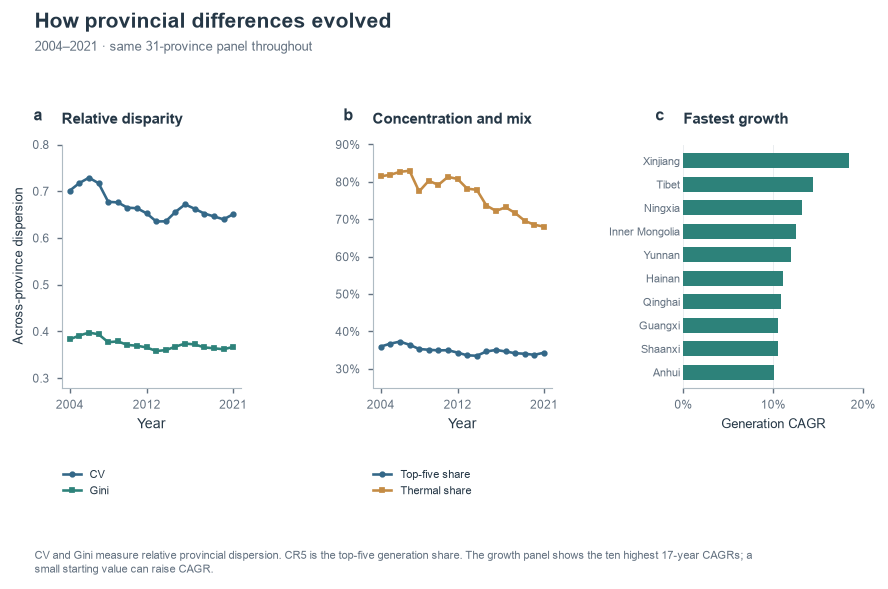

**趋势解释：**全国发电量从2004年的 **22,033.09** 增至2021年的 **85,342.48 亿千瓦时**。同期省际Gini从 **0.383** 变为 **0.367**，CV从 **0.701** 变为 **0.651**；全国火电占比从 **81.5%** 变为 **68.0%**。端点显示相对差异有所收窄，但年度曲线存在波动，不能描述为持续、单调收敛。高CAGR也可能来自较小的起点，需同时看绝对增量。

In [15]:
trend_rows = []
for col in year_columns:
    year = int(col[:-1])
    values = annual_provinces[col].astype(float)
    national_total = float(annual_wide.loc[year, "总计"])
    trend_rows.append({"Year": year, "Generation": national_total,
                       "CV": values.std(ddof=0) / values.mean(), "Gini": gini(values),
                       "CR5": values.nlargest(5).sum() / values.sum(),
                       "Thermal_share": float(annual_wide.loc[year, "火力发电总计"]) / national_total})
trend = pd.DataFrame(trend_rows).set_index("Year")
first_year, last_year = trend.index.min(), trend.index.max()
growth_comparison = annual_provinces[["地区", f"{first_year}年", f"{last_year}年"]].copy()
growth_comparison["CAGR"] = (growth_comparison[f"{last_year}年"] / growth_comparison[f"{first_year}年"]) ** (1 / (last_year - first_year)) - 1
growth_comparison["absolute_increase"] = growth_comparison[f"{last_year}年"] - growth_comparison[f"{first_year}年"]
growth_comparison["Province"] = growth_comparison["地区"].map(province_labels)
show_table(trend, 4)
show_table(growth_comparison.sort_values("CAGR", ascending=False), 4)

figure_style.historical_differences(trend, growth_comparison)

display(Markdown(
    f"**趋势解释：**全国发电量从{first_year}年的 **{trend.loc[first_year, 'Generation']:,.2f}** 增至{last_year}年的 **{trend.loc[last_year, 'Generation']:,.2f} 亿千瓦时**。"
    f"同期省际Gini从 **{trend.loc[first_year, 'Gini']:.3f}** 变为 **{trend.loc[last_year, 'Gini']:.3f}**，CV从 **{trend.loc[first_year, 'CV']:.3f}** 变为 **{trend.loc[last_year, 'CV']:.3f}**；"
    f"全国火电占比从 **{trend.loc[first_year, 'Thermal_share']:.1%}** 变为 **{trend.loc[last_year, 'Thermal_share']:.1%}**。"
    "端点显示相对差异有所收窄，但年度曲线存在波动，不能描述为持续、单调收敛。高CAGR也可能来自较小的起点，需同时看绝对增量。"))
trend.to_csv(OUTPUT_DIR / "annual_difference_trends.csv", encoding="utf-8-sig")

### 6. 月度差异验证：先匹配月份，再讨论季节性

月度表缺少各年1—2月且2024年12月缺失，不能直接相加比较全年发电量。这里仅比较2022、2023、2024年都有的3—11月。

图左保留原始亿千瓦时；图右将每月值除以该年这9个月的月均值，减弱年度规模差异。另将月总量除以当月天数，检查峰谷是否仅由月份长短造成；3—11月不涉及闰年2月。只报告样本内的高低月份，不用不足三年的不完整数据证明长期季节规律或气温因果效应。

Year,2022,2023,2024
Month,,,
3,6701.7,7172.9,7476.9
4,6085.7,6583.5,6900.8
5,6410.2,6885.8,7178.5
6,7090.3,7399.0,7685.2
7,8059.2,8461.7,8831.1
8,8248.0,8449.9,9074.2
9,6830.0,7456.1,8023.6
10,6610.0,7043.5,7310.0
11,6666.7,7309.7,7495.1


,2023_vs_2022,2024_vs_2023
Month,,
3,0.0703,0.0424
4,0.0818,0.0482
5,0.0742,0.0425
6,0.0435,0.0387
7,0.0499,0.0437
8,0.0245,0.0739
9,0.0917,0.0761
10,0.0656,0.0378
11,0.0964,0.0254


,Common_months,Matched_period_generation,Matched_period_YoY
Year,,,
2022,9,62701.8,NaN
2023,9,66762.1,0.0648
2024,9,69975.4,0.0481


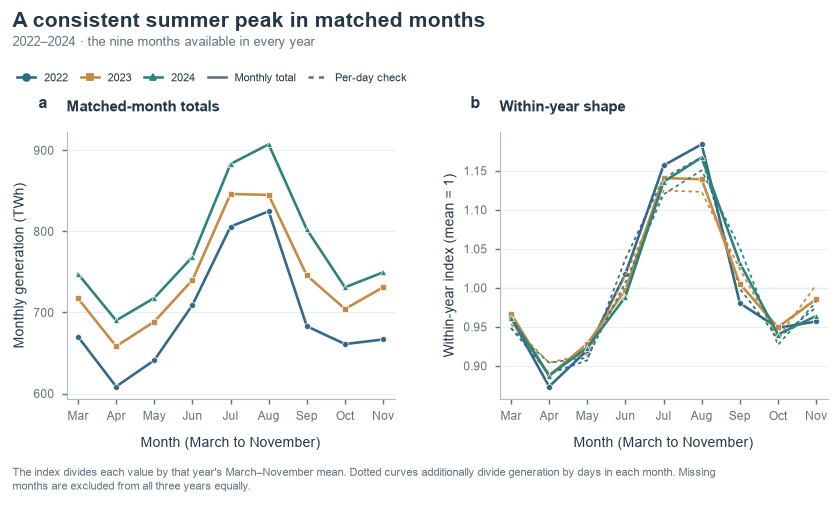

2022年月总量最高为8月、最低为4月；按日均校正后最高为8月；2023年月总量最高为7月、最低为4月；按日均校正后最高为7月；2024年月总量最高为8月、最低为4月；按日均校正后最高为8月。2023年和2024年3—11月发电量同比变化分别为 **6.5%、4.8%**，不是全年增速。样本中7—8月较高，与夏季需求假说相容；还需要温度、工业产出、节假日和来水量等同月数据才能区分具体机制。

In [16]:
monthly_check = pd.read_excel(DATA_DIR / "月度数据.xls")
parts = monthly_check["时间"].str.extract(r"(?P<Year>\d{4})年(?P<Month>\d{1,2})月").astype(int)
monthly_check = pd.concat([monthly_check, parts], axis=1)
assert not monthly_check.duplicated(["Year", "Month"]).any()
monthly_check["Generation"] = pd.to_numeric(monthly_check["发电量当期值(亿千瓦时)"], errors="raise")
assert (monthly_check.Generation > 0).all()
common_years = [2022, 2023, 2024]
months_by_year = [set(monthly_check.loc[monthly_check.Year == year, "Month"]) for year in common_years]
common_months = sorted(set.intersection(*months_by_year))
matched = monthly_check.loc[monthly_check.Year.isin(common_years) & monthly_check.Month.isin(common_months)].copy()
assert len(matched) == len(common_years) * len(common_months)
matched["Date"] = pd.to_datetime(dict(year=matched.Year, month=matched.Month, day=1))
matched["Daily_generation"] = matched.Generation / matched.Date.dt.days_in_month
matched["Within_year_index"] = matched.Generation / matched.groupby("Year").Generation.transform("mean")
matched["Within_year_daily_index"] = matched.Daily_generation / matched.groupby("Year").Daily_generation.transform("mean")
monthly_pivot = matched.pivot(index="Month", columns="Year", values="Generation").sort_index()
normalized_pivot = matched.pivot(index="Month", columns="Year", values="Within_year_index").sort_index()
daily_pivot = matched.pivot(index="Month", columns="Year", values="Within_year_daily_index").sort_index()
yoy = pd.DataFrame({"2023_vs_2022": monthly_pivot[2023] / monthly_pivot[2022] - 1,
                    "2024_vs_2023": monthly_pivot[2024] / monthly_pivot[2023] - 1})
show_table(monthly_pivot, 1)
show_table(yoy, 4)
monthly_summary = matched.groupby("Year").agg(Common_months=("Month", "size"), Matched_period_generation=("Generation", "sum"))
monthly_summary["Matched_period_YoY"] = monthly_summary.Matched_period_generation.pct_change(fill_method=None)
show_table(monthly_summary, 4)

figure_style.matched_month_patterns(monthly_pivot, normalized_pivot, daily_pivot, common_years, common_months)

peak_notes = []
for year in common_years:
    peak = int(monthly_pivot[year].idxmax())
    trough = int(monthly_pivot[year].idxmin())
    daily_peak = int(daily_pivot[year].idxmax())
    peak_notes.append(f"{year}年月总量最高为{peak}月、最低为{trough}月；按日均校正后最高为{daily_peak}月")
display(Markdown(
    "；".join(peak_notes) + "。"
    f"2023年和2024年3—11月发电量同比变化分别为 **{monthly_summary.loc[2023, 'Matched_period_YoY']:.1%}、{monthly_summary.loc[2024, 'Matched_period_YoY']:.1%}**，不是全年增速。"
    "样本中7—8月较高，与夏季需求假说相容；还需要温度、工业产出、节假日和来水量等同月数据才能区分具体机制。"))
matched.sort_values(["Year", "Month"]).to_csv(OUTPUT_DIR / "matched_month_analysis.csv", index=False, encoding="utf-8-sig")

### 7. 证据、解释与下一步验证

以下结论由前文计算动态生成。最后一列列出真正验证机制所需的数据，避免把相关关系写成原因。外部资料只提供2020年前后的制度和资源开发背景，不代替本地数据的统计检验。

In [17]:
evidence = pd.DataFrame([
    ["发电规模差异", f"2020年CR5={gap_metrics['前五省份占比 CR5']:.1%}，Gini={gap_metrics['省际Gini（等权省份）']:.3f}",
     "总量与人均排名不同，人口规模解释部分格局", "核对同年全社会用电、工业增加值、装机和利用小时"],
    ["人口关系", f"ρ={pop_relation.Spearman_rho:.3f}；人口基准调整R²={baseline['fit'].rsquared_adj:.3f}",
     "存在规模关联，不能把人口视为唯一驱动", "加入产业结构、经济规模、城市化和跨省交易数据"],
    ["煤炭与火电", f"22省ρ={coal_relation.Spearman_rho:.3f}；控制人口的煤炭系数={coal_ci.coefficient:.3f}",
     "支持资源与火电布局相关的假说；2023/2020错位、9省缺失，证据有限", "补2020煤炭、煤电而非全部火电、燃料调运及缺失原因；不将缺失补零"],
    ["水资源与结构", f"非火电占比ρ={water_share_relation.Spearman_rho:.3f}，总量ρ={water_total_relation.Spearman_rho:.3f}",
     "与发电结构的关联比与总量的关联明显；不能把非火电直接叫水电", "确认水资源年份，补同年水电量、落差、可开发水能、装机、来水和外送能力"],
    ["长期变化", f"Gini {trend.loc[first_year, 'Gini']:.3f}→{trend.loc[last_year, 'Gini']:.3f}",
     "端点的相对差异收窄，年度过程有波动", "扩充最新同口径年度序列和逐年人口；核验统计口径变化"],
    ["月度高低", "2022—2024共同3—11月，比较月总量及日均值",
     "样本中夏季月份较高；尚未验证气温机制", "补1—2月、2024年12月及更长序列，再结合温度、工业产出与来水量建模"],
], columns=["问题", "计算证据", "允许的解释", "后续验证"])
display(evidence)

summary_text = f"""# 中国省际发电差异：分析结论

分析范围：大陆31省；发电和人口基准年2020；年度2004—2021；月度2022—2024共同3—11月。

1. **规模与结构差异均明显。** 2020年前五省发电占比{gap_metrics['前五省份占比 CR5']:.1%}，省际Gini为{gap_metrics['省际Gini（等权省份）']:.3f}。总量前五为{'、'.join(ranked.head(5)['地区'])}；人均前五为{'、'.join(pc_ranked.head(5)['地区'])}。人均发电量不是人均用电量，也不能用于判定净外送。
2. **人口与发电规模存在稳定的正向排序关系。** Spearman ρ={pop_relation.Spearman_rho:.3f}，逐省剔除范围{pop_relation.LOO_rho_min:.3f}—{pop_relation.LOO_rho_max:.3f}，置换Holm校正p={pop_relation.Holm_p:.4f}。人口对数基准模型调整R²={baseline['fit'].rsquared_adj:.3f}；它描述关联拟合，不是人口导致差异的比例。
3. **煤炭与火电存在探索性关联。** 22个完整省份的ρ={coal_relation.Spearman_rho:.3f}，Holm校正p={coal_relation.Holm_p:.4f}；控制人口后煤炭对数系数{coal_ci.coefficient:.3f}，HC3区间[{coal_ci.HC3_CI_low:.3f}, {coal_ci.HC3_CI_high:.3f}]，逐省剔除系数范围[{coal_ci.LOO_coefficient_min:.3f}, {coal_ci.LOO_coefficient_max:.3f}]。同一22省火电模型的留一省对数RMSE由{coal_baseline_rmse:.3f}变为{coal_added_rmse:.3f}。但煤炭为2023年、火电为2020年，缺失9省未补零，不能据此识别2020年煤炭的因果影响；火电不等于煤电。
4. **水资源更贴近结构差异，未支持其与总发电量有很强单调关系。** 水资源与非火电占比ρ={water_share_relation.Spearman_rho:.3f}（Holm p={water_share_relation.Holm_p:.4f}），与总量ρ={water_total_relation.Spearman_rho:.3f}（Holm p={water_total_relation.Holm_p:.4f}）。控制人口后水资源系数{water_ci.coefficient:.3f}，HC3区间[{water_ci.HC3_CI_low:.3f}, {water_ci.HC3_CI_high:.3f}]；留一省对数RMSE由{water_baseline_rmse:.3f}变为{water_added_rmse:.3f}。水资源年份未标注，非火电并非水电，水量也不等于可开发水能，因此只是结构关联线索。
5. **长期总量增加不等于差异扩大。** {first_year}—{last_year}年全国发电量从{trend.loc[first_year, 'Generation']:,.2f}增至{trend.loc[last_year, 'Generation']:,.2f}亿千瓦时；Gini从{trend.loc[first_year, 'Gini']:.3f}变为{trend.loc[last_year, 'Gini']:.3f}，CV从{trend.loc[first_year, 'CV']:.3f}变为{trend.loc[last_year, 'CV']:.3f}，火电占比从{trend.loc[first_year, 'Thermal_share']:.1%}变为{trend.loc[last_year, 'Thermal_share']:.1%}。相对差异端点有所收窄，过程中存在波动。
6. **月度样本显示夏季月份较高。** {'；'.join(peak_notes)}。2023、2024共同3—11月同比为{monthly_summary.loc[2023, 'Matched_period_YoY']:.1%}、{monthly_summary.loc[2024, 'Matched_period_YoY']:.1%}，不能称为全年增长。尚未用温度或工业产出数据验证原因。

## 解释与证据的边界

可以将人口规模、资源禀赋、装机布局和电网交易列为差异解释框架，其中本Notebook直接验证了人口及资源的统计关联。国家能源局2020年答复说明四川水电开发与外送通道、消纳条件有关，这支持“资源不能自动转化为发电量”的机制背景，并不证明本研究中各省残差的具体成因。[国家能源局答复](https://zfxxgk.nea.gov.cn/2020-09/07/c_139420065.htm)

31省为研究对象全集，普通置换与HC3参考区间不能处理所有空间依赖或遗漏变量。不能根据相关系数或p值宣称因果。水资源缺年份、煤炭跨年和缺失、缺水电细分及用电/交易数据，是主要限制。

建议下一步优先补充2020年各省煤炭产量、水电/核电/风电/光伏/煤电分项、装机与利用小时、工业增加值及跨省净送受电，再做同年多变量与空间依赖检验。月度部分先补齐月份，再加入气温、来水和工业产出。

## 来源

- 本地数据：`data/分省年度数据.csv`、`data/分省年度数据(转置).csv`、`data/火力发电数据2020.xls`、`data/省份地理信息.xlsx`、`data/煤产量数据.xls`、`data/水资源总量.xls`、`data/月度数据.xls`。发电单位依原Notebook及列名使用亿千瓦时，煤炭万吨、水资源亿立方米；本地原表缺少完整来源说明，仍需回查原始统计口径。
- [国家统计局：第七次全国人口普查公报（第三号），2021-05-11](https://www.stats.gov.cn/sj/zxfb/202302/t20230203_1901083.html)：31省人口及四大区域划分。31省人口合计不含单列的现役军人。
- [国家能源局：对十三届全国人大三次会议第4441号建议的答复，2020-09-07](https://zfxxgk.nea.gov.cn/2020-09/07/c_139420065.htm)：水电外送与消纳的机制背景。
- [SciPy：Spearman相关方法说明](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.spearmanr.html)：小样本置换检验参考。

全部计算、逐省表、稳健性表和图表见 `1.ipynb` 的“省际差异、关系验证与解释”部分；图片和CSV随重跑更新至 `analysis_outputs/`。
"""
display(Markdown(summary_text))
(OUTPUT_DIR / "analysis_summary.md").write_text(summary_text, encoding="utf-8")
analysis.to_csv(OUTPUT_DIR / "province_analysis_data.csv", index=False, encoding="utf-8-sig")

,问题,计算证据,允许的解释,后续验证
0,发电规模差异,2020年CR5=33.7%，Gini=0.362,总量与人均排名不同，人口规模解释部分格局,核对同年全社会用电、工业增加值、装机和利用小时
1,人口关系,ρ=0.680；人口基准调整R²=0.546,存在规模关联，不能把人口视为唯一驱动,加入产业结构、经济规模、城市化和跨省交易数据
2,煤炭与火电,22省ρ=0.477；控制人口的煤炭系数=0.219,支持资源与火电布局相关的假说；2023/2020错位、9省缺失，证据有限,补2020煤炭、煤电而非全部火电、燃料调运及缺失原因；不将缺失补零
3,水资源与结构,非火电占比ρ=0.686，总量ρ=0.150,与发电结构的关联比与总量的关联明显；不能把非火电直接叫水电,确认水资源年份，补同年水电量、落差、可开发水能、装机、来水和外送能力
4,长期变化,Gini 0.383→0.367,端点的相对差异收窄，年度过程有波动,扩充最新同口径年度序列和逐年人口；核验统计口径变化
5,月度高低,2022—2024共同3—11月，比较月总量及日均值,样本中夏季月份较高；尚未验证气温机制,补1—2月、2024年12月及更长序列，再结合温度、工业产出与来水量建模


# 中国省际发电差异：分析结论

分析范围：大陆31省；发电和人口基准年2020；年度2004—2021；月度2022—2024共同3—11月。

1. **规模与结构差异均明显。** 2020年前五省发电占比33.7%，省际Gini为0.362。总量前五为内蒙古自治区、山东省、广东省、江苏省、四川省；人均前五为宁夏回族自治区、内蒙古自治区、青海省、新疆维吾尔自治区、山西省。人均发电量不是人均用电量，也不能用于判定净外送。
2. **人口与发电规模存在稳定的正向排序关系。** Spearman ρ=0.680，逐省剔除范围0.647—0.784，置换Holm校正p=0.0003。人口对数基准模型调整R²=0.546；它描述关联拟合，不是人口导致差异的比例。
3. **煤炭与火电存在探索性关联。** 22个完整省份的ρ=0.477，Holm校正p=0.0487；控制人口后煤炭对数系数0.219，HC3区间[0.058, 0.380]，逐省剔除系数范围[0.171, 0.246]。同一22省火电模型的留一省对数RMSE由0.960变为0.819。但煤炭为2023年、火电为2020年，缺失9省未补零，不能据此识别2020年煤炭的因果影响；火电不等于煤电。
4. **水资源更贴近结构差异，未支持其与总发电量有很强单调关系。** 水资源与非火电占比ρ=0.686（Holm p=0.0003），与总量ρ=0.150（Holm p=0.4198）。控制人口后水资源系数-0.085，HC3区间[-0.417, 0.248]；留一省对数RMSE由0.676变为0.725。水资源年份未标注，非火电并非水电，水量也不等于可开发水能，因此只是结构关联线索。
5. **长期总量增加不等于差异扩大。** 2004—2021年全国发电量从22,033.09增至85,342.48亿千瓦时；Gini从0.383变为0.367，CV从0.701变为0.651，火电占比从81.5%变为68.0%。相对差异端点有所收窄，过程中存在波动。
6. **月度样本显示夏季月份较高。** 2022年月总量最高为8月、最低为4月；按日均校正后最高为8月；2023年月总量最高为7月、最低为4月；按日均校正后最高为7月；2024年月总量最高为8月、最低为4月；按日均校正后最高为8月。2023、2024共同3—11月同比为6.5%、4.8%，不能称为全年增长。尚未用温度或工业产出数据验证原因。

## 解释与证据的边界

可以将人口规模、资源禀赋、装机布局和电网交易列为差异解释框架，其中本Notebook直接验证了人口及资源的统计关联。国家能源局2020年答复说明四川水电开发与外送通道、消纳条件有关，这支持“资源不能自动转化为发电量”的机制背景，并不证明本研究中各省残差的具体成因。[国家能源局答复](https://zfxxgk.nea.gov.cn/2020-09/07/c_139420065.htm)

31省为研究对象全集，普通置换与HC3参考区间不能处理所有空间依赖或遗漏变量。不能根据相关系数或p值宣称因果。水资源缺年份、煤炭跨年和缺失、缺水电细分及用电/交易数据，是主要限制。

建议下一步优先补充2020年各省煤炭产量、水电/核电/风电/光伏/煤电分项、装机与利用小时、工业增加值及跨省净送受电，再做同年多变量与空间依赖检验。月度部分先补齐月份，再加入气温、来水和工业产出。

## 来源

- 本地数据：`data/分省年度数据.csv`、`data/分省年度数据(转置).csv`、`data/火力发电数据2020.xls`、`data/省份地理信息.xlsx`、`data/煤产量数据.xls`、`data/水资源总量.xls`、`data/月度数据.xls`。发电单位依原Notebook及列名使用亿千瓦时，煤炭万吨、水资源亿立方米；本地原表缺少完整来源说明，仍需回查原始统计口径。
- [国家统计局：第七次全国人口普查公报（第三号），2021-05-11](https://www.stats.gov.cn/sj/zxfb/202302/t20230203_1901083.html)：31省人口及四大区域划分。31省人口合计不含单列的现役军人。
- [国家能源局：对十三届全国人大三次会议第4441号建议的答复，2020-09-07](https://zfxxgk.nea.gov.cn/2020-09/07/c_139420065.htm)：水电外送与消纳的机制背景。
- [SciPy：Spearman相关方法说明](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.spearmanr.html)：小样本置换检验参考。

全部计算、逐省表、稳健性表和图表见 `1.ipynb` 的“省际差异、关系验证与解释”部分；图片和CSV随重跑更新至 `analysis_outputs/`。
